In [1]:
import random
import zipfile
from collections import Counter
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
from google.colab import files

COCO_NAMES = [
    "person", "bicycle", "car", "motorcycle", "airplane", "bus", "train", "truck", "boat",
    "traffic light", "fire hydrant", "stop sign", "parking meter", "bench", "bird", "cat",
    "dog", "horse", "sheep", "cow", "elephant", "bear", "zebra", "giraffe", "backpack",
    "umbrella", "handbag", "tie", "suitcase", "frisbee", "skis", "snowboard", "sports ball",
    "kite", "baseball bat", "baseball glove", "skateboard", "surfboard", "tennis racket",
    "bottle", "wine glass", "cup", "fork", "knife", "spoon", "bowl", "banana", "apple",
    "sandwich", "orange", "broccoli", "carrot", "hot dog", "pizza", "donut", "cake", "chair",
    "couch", "potted plant", "bed", "dining table", "toilet", "tv", "laptop", "mouse",
    "remote", "keyboard", "cell phone", "microwave", "oven", "toaster", "sink",
    "refrigerator", "book", "clock", "vase", "scissors", "teddy bear", "hair drier",
    "toothbrush"
]

TRAFFIC_CLASSES = {
    "person", "bicycle", "car", "motorcycle", "bus", "truck", "traffic light", "stop sign"
}
TRAFFIC_IDS = {COCO_NAMES.index(name) for name in TRAFFIC_CLASSES}

print("Step 1 complete: Libraries and traffic class IDs initialized.")

Step 1 complete: Libraries and traffic class IDs initialized.


In [2]:
print("=" * 65)
print("       COCO TRAFFIC DATASET EXPLORATION")
print("=" * 65)
print("\nPLEASE UPLOAD YOUR COCO128 ZIP FILE\n")

uploaded = files.upload()
if not uploaded:
    raise RuntimeError("No file uploaded. Please run Step 2 again and select coco128.zip.")

zip_name = next(iter(uploaded.keys()))
extract_dir = Path("/content/coco128_extracted")
extract_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as zf:
    zf.extractall(extract_dir)

print(f"\nSaving {zip_name} to {zip_name}")
print("Dataset extracted successfully!")

       COCO TRAFFIC DATASET EXPLORATION

PLEASE UPLOAD YOUR COCO128 ZIP FILE



Saving photo_6323421023977542514_y.jpg to photo_6323421023977542514_y.jpg


BadZipFile: File is not a zip file

In [3]:
print("=" * 65)
print("       COCO TRAFFIC DATASET EXPLORATION")
print("=" * 65)
print("\nPLEASE UPLOAD YOUR COCO128 ZIP FILE\n")

uploaded = files.upload()
if not uploaded:
    raise RuntimeError("No file uploaded. Please run Step 2 again and select coco128.zip.")

zip_name = next(iter(uploaded.keys()))
extract_dir = Path("/content/coco128_extracted")
extract_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as zf:
    zf.extractall(extract_dir)

print(f"\nSaving {zip_name} to {zip_name}")
print("Dataset extracted successfully!")

       COCO TRAFFIC DATASET EXPLORATION

PLEASE UPLOAD YOUR COCO128 ZIP FILE



Saving WPS Office Installer.app.zip to WPS Office Installer.app.zip

Saving WPS Office Installer.app.zip to WPS Office Installer.app.zip
Dataset extracted successfully!


In [4]:
img_exts = {".jpg", ".jpeg", ".png"}
image_files = sorted([p for p in extract_dir.rglob("*") if p.suffix.lower() in img_exts])
label_files = sorted([p for p in extract_dir.rglob("*.txt") if p.name.lower() != "readme.txt"])

label_map = {p.stem: p for p in label_files}

traffic_samples = []
class_counts = Counter()

for img_path in image_files:
    lbl_path = label_map.get(img_path.stem)
    if not lbl_path or not lbl_path.exists():
        continue

    boxes = []
    with open(lbl_path, "r") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 5:
                continue
            cls_id = int(float(parts[0]))
            cx, cy, w, h = map(float, parts[1:5])
            if cls_id in TRAFFIC_IDS:
                boxes.append((cls_id, cx, cy, w, h))
                class_counts[COCO_NAMES[cls_id]] += 1

    if boxes:
        traffic_samples.append((img_path, boxes))

print(f"Total photographs: {len(image_files)}")
print(f"Total annotation files: {len(label_files)}")
print(f"\nTRAFFIC IMAGES FOUND: {len(traffic_samples)}")
print("Traffic object counts:", dict(class_counts))

Total photographs: 0
Total annotation files: 0

TRAFFIC IMAGES FOUND: 0
Traffic object counts: {}



REAL TRAFFIC PHOTOGRAPHS WITH BOUNDING BOXES



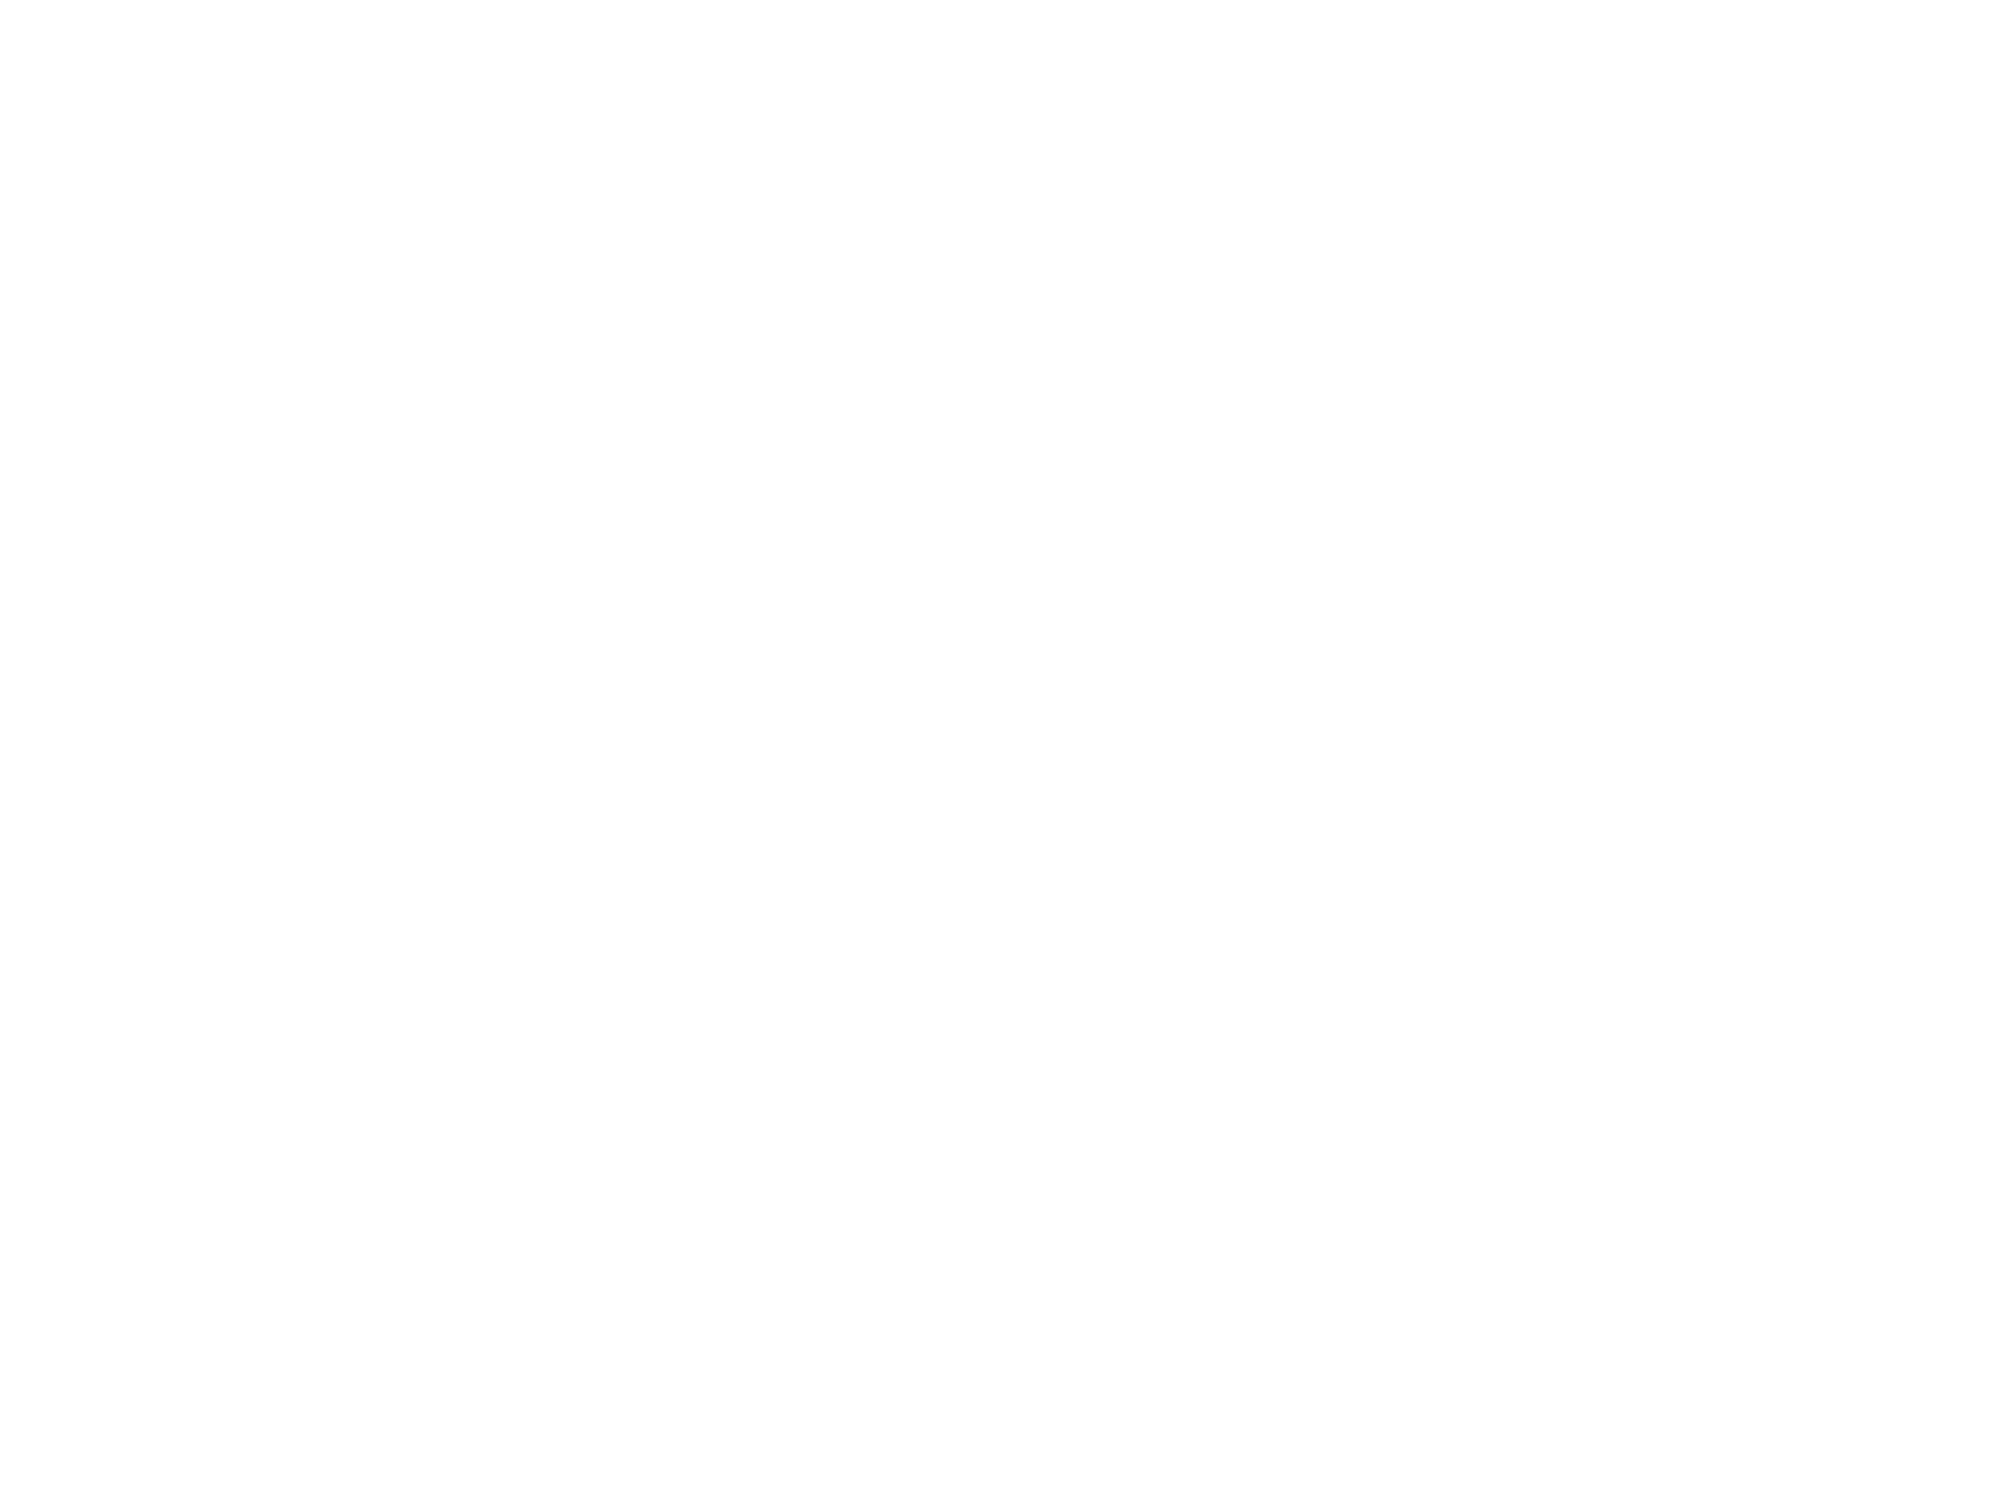

In [5]:
print("\nREAL TRAFFIC PHOTOGRAPHS WITH BOUNDING BOXES\n")

sample_to_show = random.sample(traffic_samples, k=min(9, len(traffic_samples)))

fig, axes = plt.subplots(3, 3, figsize=(20, 15))
axes = axes.flatten()

for ax, (img_path, boxes) in zip(axes, sample_to_show):
    img_bgr = cv2.imread(str(img_path))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h_img, w_img, _ = img_rgb.shape

    for cls_id, cx, cy, bw, bh in boxes:
        x1 = int((cx - bw / 2) * w_img)
        y1 = int((cy - bh / 2) * h_img)
        x2 = int((cx + bw / 2) * w_img)
        y2 = int((cy + bh / 2) * h_img)

        cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (255, 50, 50), 2)
        label = COCO_NAMES[cls_id]
        cv2.putText(
            img_rgb,
            label,
            (x1, max(y1 - 6, 12)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.55,
            (255, 255, 0),
            2,
        )

    ax.imshow(img_rgb)
    ax.set_title(img_path.name, fontsize=11)
    ax.axis("off")

for ax in axes[len(sample_to_show):]:
    ax.axis("off")

plt.tight_layout()
plt.show()